# Outlier

A data point that is very different from the rest of the data in a set is called outlier

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('loan_data_set.csv')
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [4]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [5]:
df.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

## Detecting Outliers

### Using BoxPlot

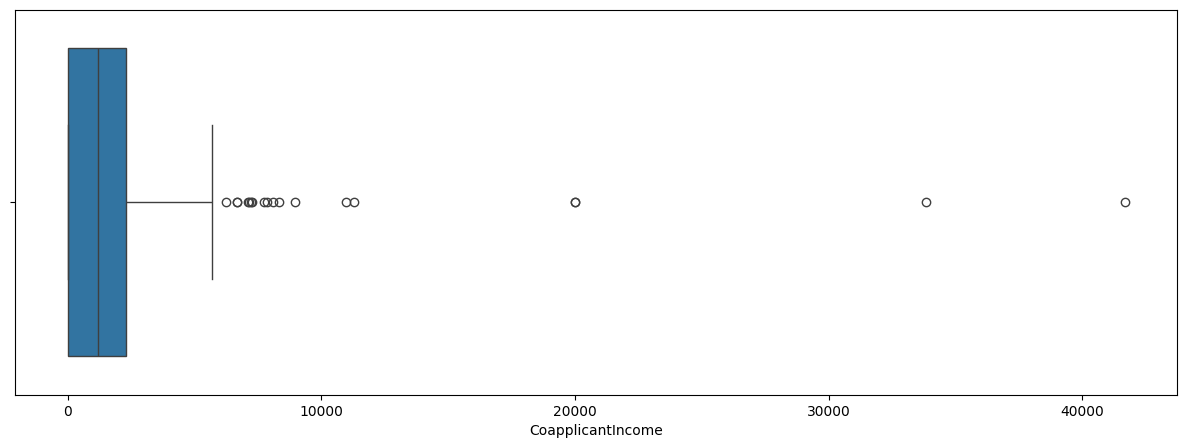

In [6]:
plt.figure(figsize=(15, 5)) 
sns.boxplot(x="CoapplicantIncome", data=df)
plt.show()

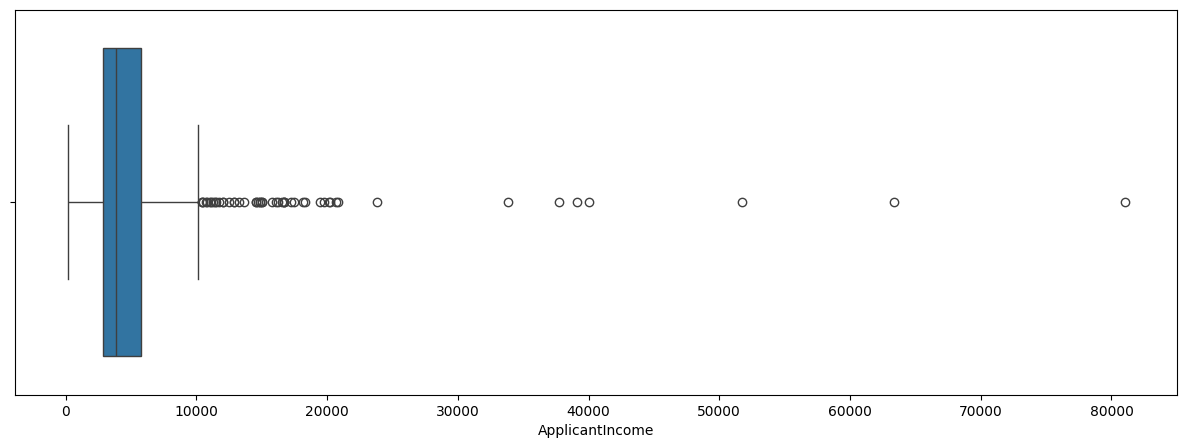

In [7]:
plt.figure(figsize=(15, 5)) 
sns.boxplot(x="ApplicantIncome", data=df)
plt.show()

### Using Distribution Curve (Normal Distribution)

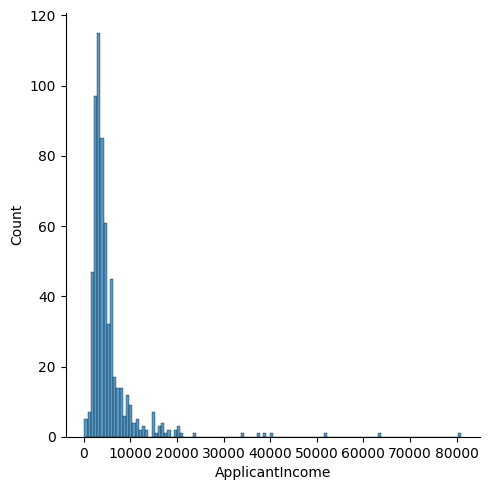

In [8]:
sns.displot(df['ApplicantIncome'])
plt.show()

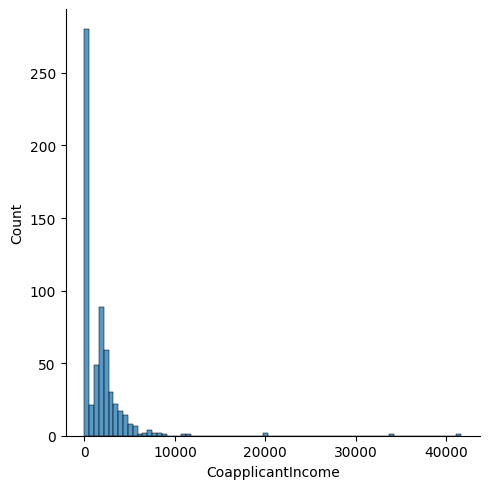

In [9]:
sns.displot(df['CoapplicantIncome'])
plt.show()

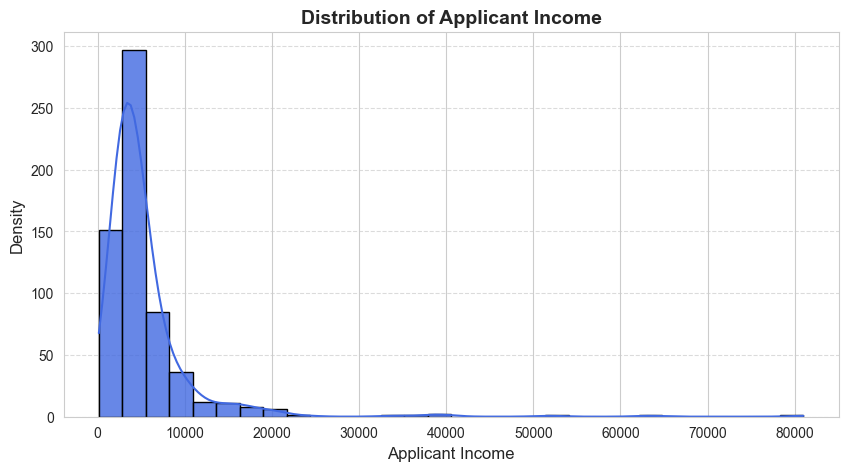

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set a beautiful theme
sns.set_style("whitegrid")  # Options: "white", "dark", "whitegrid", "darkgrid", "ticks"

# Create a beautiful distribution plot
plt.figure(figsize=(10, 5))  # Adjust figure size
sns.histplot(df['ApplicantIncome'], bins=30, kde=True, color="royalblue", edgecolor="black", alpha=0.8)

# Improve Labels & Title
plt.title("Distribution of Applicant Income", fontsize=14, fontweight="bold")
plt.xlabel("Applicant Income", fontsize=12)
plt.ylabel("Density", fontsize=12)

# Show Grid
plt.grid(axis='y', linestyle="--", alpha=0.7)

plt.show()


---

## Removing Outliers

### Using IQR (InterQuartile Range) method

In [11]:
df = pd.read_csv('loan_data_set.csv')
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


In [12]:
df.shape

(614, 13)

In [13]:
q1 = df['CoapplicantIncome'].quantile(0.25) 
q3 = df['CoapplicantIncome'].quantile(0.75) 

In [14]:
IQR = q3 - q1

In [15]:
min_range = q1 - (1.5 * IQR)
max_range = q3 + (1.5 * IQR)

In [16]:
print(q1)
print(q3)

print(IQR)

print(min_range)
print(max_range)

0.0
2297.25
2297.25
-3445.875
5743.125


In [17]:
# All above things are directly given as
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [18]:
new_df = df[df['CoapplicantIncome'] <= max_range]

new_df.shape

(596, 13)

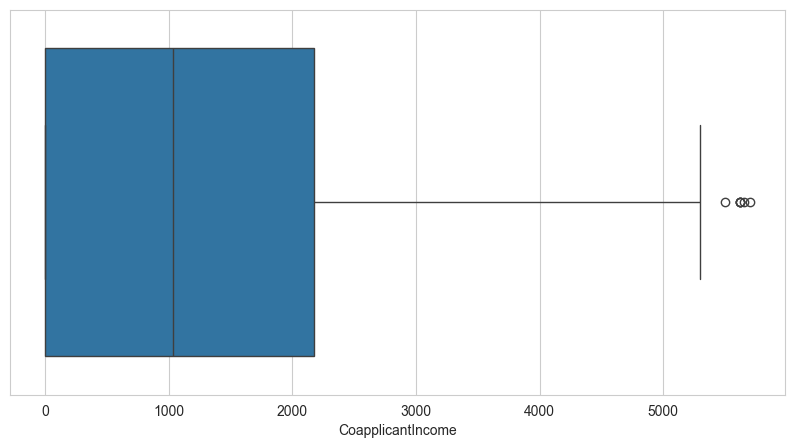

In [19]:
plt.figure(figsize=(10, 5)) 
sns.boxplot(x="CoapplicantIncome", data=new_df)
plt.show()

### Using Z-Score

In [20]:
df = pd.read_csv('loan_data_set.csv')
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


#### Direct Approach

In [21]:
mean_value = df['ApplicantIncome'].mean()
standard_dev_value = df['ApplicantIncome'].std()

mean_value, standard_dev_value

(5403.459283387622, 6109.041673387178)

In [22]:
min_range = mean_value - (3 * standard_dev_value)
max_range = mean_value + (3 * standard_dev_value)

min_range, max_range

(-12923.66573677391, 23730.584303549156)

In [23]:
direct_approach_df = df[df['ApplicantIncome']<=max_range]

In [24]:
direct_approach_df.shape

(606, 13)

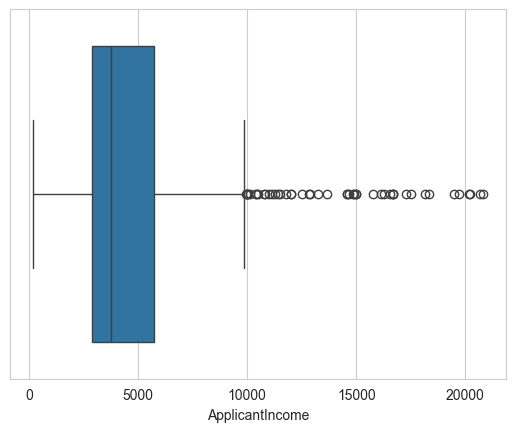

In [25]:
# sns.displot(direct_approach_df['ApplicantIncome'])
sns.boxplot(x = 'ApplicantIncome', data = direct_approach_df )
plt.show()

In [26]:
# z = ( x - mean ) / std
z_score = ( df['CoapplicantIncome'] - df['CoapplicantIncome'].mean() ) / df['CoapplicantIncome'].std()

z_score

0     -0.554036
1     -0.038700
2     -0.554036
3      0.251774
4     -0.554036
         ...   
609   -0.554036
610   -0.554036
611   -0.472019
612   -0.554036
613   -0.554036
Name: CoapplicantIncome, Length: 614, dtype: float64

In [27]:
df['z_score'] = z_score

In [28]:
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z_score
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,-0.554036
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.038700
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.554036


In [29]:
threshold = 3 # commonly 3

In [30]:
df = df[df['z_score'] < threshold] 
df.shape

(608, 14)

---